# Exploratory data analysis: UCI Default of Credit Card Clients

Exploration only. **Nothing in the pipeline imports this notebook.** It documents the data facts that the
validation schema (`src/data/validation.py`) and preprocessing (`src/features/preprocessing.py`) rely on.

Run from the repo root after `dvc pull -r dagshub` (needs `data/raw/credit_default.csv`).
Point `DATA` at the synthetic file (`python -m src.data.synthetic`) only for a dry run: numbers are then not real.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA = Path("data/raw/credit_default.csv")   # real data; dry run: data/smoke/raw/credit_default.csv
TARGET, ID = "default", "customer_id"
df = pd.read_csv(DATA)
PAY = [f"PAY_{i}" for i in range(1, 7)]
BILL = [f"BILL_AMT{i}" for i in range(1, 7)]
PAYAMT = [f"PAY_AMT{i}" for i in range(1, 7)]
print(DATA, df.shape)
df.head()

data\raw\credit_default.csv (30000, 25)


,customer_id,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 1. Shape, types, missing values, duplicates

In [2]:
print(df.dtypes.value_counts())
print("nulls:", int(df.isna().sum().sum()))
print("duplicate IDs:", int(df[ID].duplicated().sum()))
print("duplicate rows ignoring ID:", int(df.drop(columns=[ID]).duplicated().sum()))
df.describe().T

int64    25
Name: count, dtype: int64
nulls: 0
duplicate IDs: 0
duplicate rows ignoring ID: 35


,count,mean,std,min,25%,50%,75%,max
customer_id,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_1,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


## 2. Class balance (the target is imbalanced, which is why the models use class weights)

default rate: 22.12%  (positives 6,636 of 30,000)


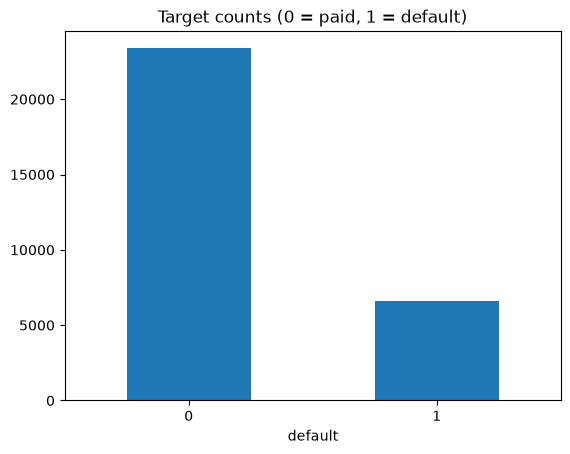

In [3]:
rate = df[TARGET].mean()
print(f"default rate: {rate:.2%}  (positives {int(df[TARGET].sum()):,} of {len(df):,})")
df[TARGET].value_counts().plot.bar(title="Target counts (0 = paid, 1 = default)", rot=0)
plt.show()

## 3. Categorical columns and the undocumented codes
The UCI documentation lists `EDUCATION` 1-4 and `MARRIAGE` 1-3, but the file also contains `EDUCATION` 0/5/6 and `MARRIAGE` 0.
They are kept (the schema allows them) and handled in preprocessing. This section shows how many rows are affected
and whether they behave differently.

In [4]:
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    t = df.groupby(col)[TARGET].agg(rows="size", default_rate="mean")
    t["share"] = t["rows"] / len(df)
    print(col); display(t.round(4)); print()

SEX


,rows,default_rate,share
SEX,,,
1,11888,0.2417,0.3963
2,18112,0.2078,0.6037



EDUCATION


,rows,default_rate,share
EDUCATION,,,
0,14,0.0000,0.0005
1,10585,0.1923,0.3528
2,14030,0.2373,0.4677
3,4917,0.2516,0.1639
4,123,0.0569,0.0041
5,280,0.0643,0.0093
6,51,0.1569,0.0017



MARRIAGE


,rows,default_rate,share
MARRIAGE,,,
0,54,0.0926,0.0018
1,13659,0.2347,0.4553
2,15964,0.2093,0.5321
3,323,0.2601,0.0108


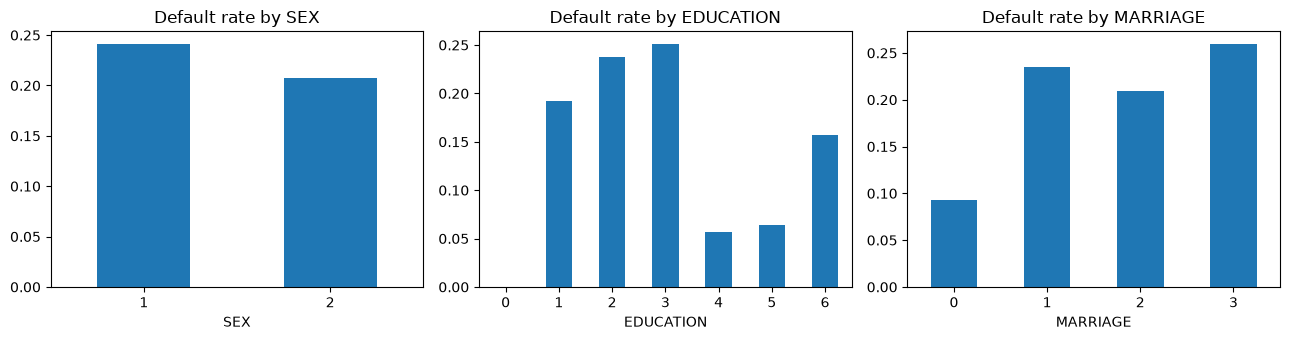

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["SEX", "EDUCATION", "MARRIAGE"]):
    df.groupby(col)[TARGET].mean().plot.bar(ax=ax, rot=0, title=f"Default rate by {col}")
plt.tight_layout(); plt.show()

## 4. `PAY_*` coding
`PAY_k` is the repayment status in month k: **-2** no consumption, **-1** paid in full, **0** revolving credit / minimum paid,
**1..8** months of delay. It is a *status code*, not a plain ordinal amount, so the engineered features
(max/mean delay, count of delinquent months) treat values <= 0 as "not late".

In [6]:
all_pay = pd.concat([df[c] for c in PAY])
print(all_pay.value_counts().sort_index())
print("share of PAY values > 0 (late):", round(float((all_pay > 0).mean()), 4))
df.groupby("PAY_1")[TARGET].agg(rows="size", default_rate="mean").round(3)

-2    24415
-1    34640
 0    95919
 1     3722
 2    18964
 3     1430
 4      453
 5      137
 6       74
 7      218
 8       28
Name: count, dtype: int64
share of PAY values > 0 (late): 0.139


,rows,default_rate
PAY_1,,
-2,2759,0.132
-1,5686,0.168
0,14737,0.128
1,3688,0.339
2,2667,0.691
3,322,0.758
4,76,0.684
5,26,0.500
6,11,0.545


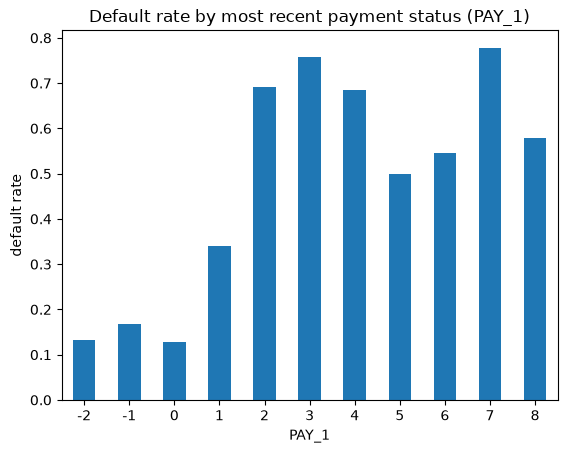

In [7]:
ax = df.groupby("PAY_1")[TARGET].mean().plot.bar(rot=0, title="Default rate by most recent payment status (PAY_1)")
ax.set_ylabel("default rate"); plt.show()

## 5. Numeric ranges and skew (what the validation ranges and scaling must cope with)

In [8]:
num = ["LIMIT_BAL", "AGE"] + BILL + PAYAMT
df[num].agg(["min", "median", "mean", "max", "skew"]).T

,min,median,mean,max,skew
LIMIT_BAL,10000.0,140000.0,167484.322667,1000000.0,0.992867
AGE,21.0,34.0,35.485500,79.0,0.732246
BILL_AMT1,-165580.0,22381.5,51223.330900,964511.0,2.663861
BILL_AMT2,-69777.0,21200.0,49179.075167,983931.0,2.705221
BILL_AMT3,-157264.0,20088.5,47013.154800,1664089.0,3.087830
BILL_AMT4,-170000.0,19052.0,43262.948967,891586.0,2.821965
BILL_AMT5,-81334.0,18104.5,40311.400967,927171.0,2.876380
BILL_AMT6,-339603.0,17071.0,38871.760400,961664.0,2.846645
PAY_AMT1,0.0,2100.0,5663.580500,873552.0,14.668364
PAY_AMT2,0.0,2009.0,5921.163500,1684259.0,30.453817


negative bills: {'BILL_AMT1': 590, 'BILL_AMT2': 669, 'BILL_AMT3': 655, 'BILL_AMT4': 675, 'BILL_AMT5': 655, 'BILL_AMT6': 688}
non-positive limit rows: 0


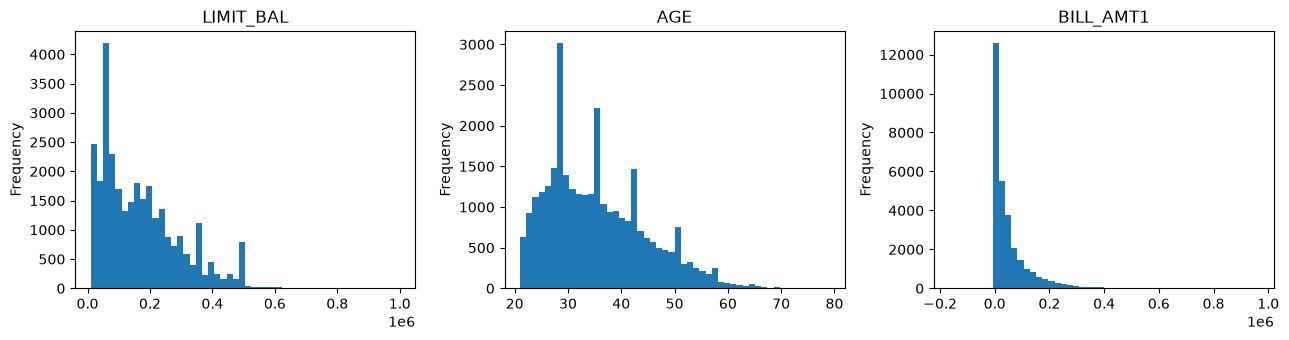

In [9]:
print("negative bills:", {c: int((df[c] < 0).sum()) for c in BILL if (df[c] < 0).any()})
print("non-positive limit rows:", int((df["LIMIT_BAL"] <= 0).sum()))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["LIMIT_BAL", "AGE", "BILL_AMT1"]):
    df[col].plot.hist(bins=50, ax=ax, title=col)
plt.tight_layout(); plt.show()

## 6. Which raw features relate to the target (sanity check, not feature selection)

In [10]:
corr = df.drop(columns=[ID]).corr(numeric_only=True)[TARGET].drop(TARGET)
corr.sort_values(key=abs, ascending=False).head(12).round(3)

PAY_1        0.325
PAY_2        0.264
PAY_3        0.235
PAY_4        0.217
PAY_5        0.204
PAY_6        0.187
LIMIT_BAL   -0.154
PAY_AMT1    -0.073
PAY_AMT2    -0.059
PAY_AMT4    -0.057
PAY_AMT3    -0.056
PAY_AMT5    -0.055
Name: default, dtype: float64

In [11]:
df["utilisation1"] = (df["BILL_AMT1"] / df["LIMIT_BAL"]).clip(-1, 5)
df["max_delay"] = df[PAY].clip(lower=0).max(axis=1)
df["n_late"] = (df[PAY] > 0).sum(axis=1)
print(df[["utilisation1", "max_delay", "n_late", TARGET]].corr()[TARGET].round(3))
df.groupby("n_late")[TARGET].agg(rows="size", default_rate="mean").round(3)

utilisation1    0.086
max_delay       0.370
n_late          0.398
default         1.000
Name: default, dtype: float64


,rows,default_rate
n_late,,
0,19931,0.117
1,4426,0.298
2,1899,0.388
3,1154,0.509
4,951,0.573
5,298,0.574
6,1341,0.703


## 7. Sensitive attributes
`SEX`, `MARRIAGE`, `AGE` are **not model inputs** (`features.exclude_sensitive_from_model: true`); they are used only to audit
outcomes (`docs/fairness.md`). The default rate by age band below is the base-rate context for that audit.

In [12]:
bands = pd.cut(df["AGE"], [0, 29, 39, 49, 59, 200], labels=["<30", "30-39", "40-49", "50-59", "60+"])
df.groupby(bands, observed=True)[TARGET].agg(rows="size", default_rate="mean").round(3)

,rows,default_rate
AGE,,
<30,9618,0.228
30-39,11238,0.203
40-49,6464,0.230
50-59,2341,0.249
60+,339,0.283


## 8. Findings to carry into the pipeline

- **Class balance.** 6,636 of 30,000 customers defaulted (22.12%). The selected random forest uses balanced subsample weights. The evaluation reports precision and recall alongside ROC-AUC.
- **Undocumented categories.** 345 rows have EDUCATION 0, 5, or 6, with a default rate of 7.54%. Preprocessing groups these codes with category 4 (other). 54 rows have MARRIAGE 0, with a default rate of 9.26%. Marital status is retained for the fairness audit and excluded from model inputs.
- **Payment history.** The delay features count positive PAY codes as months late. Codes at or below zero contribute zero months of delay. This matters because the maximum payment delay was the top explanation factor in the trained model.
- **Amounts and scaling.** 1,930 customers have a negative bill in at least one month. First-month bills have a median of 22,382 and a maximum of 964,511. The pipeline preserves signed balances and fits its numeric standardization on the training split.
- **Duplicates.** Customer IDs contain 0 duplicates. Ignoring the ID leaves 35 repeated rows. The version used for training retains these records because matching observed values alone do not establish that two customer IDs refer to the same person.
